# Иерархическая кластеризация. Тюков Даниил

**Данные:** экономические условия в 48 городах мира в 1991 году (отдел экономических исследований банка UBS, Швейцария).

| Переменная | Описание |
|---|---|
| `City` | Название города |
| `Work` | Взвешенное среднее число рабочих часов в год по 12 профессиям |
| `Price` | Индекс цен 112 товаров и услуг, включая аренду жилья |
| `Salary` | Индекс зарплаты за час работы по 12 профессиям после налогов |

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

## 1. Загрузка и очистка данных

In [3]:
df_raw = pd.read_csv("Econom_Cities_data.csv", sep=";", decimal=",")
df_raw.head()

,City,Work,Price,Salary
0,Amsterdam,1714,65.6,49.0
1,Athens,1792,53.8,30.4
2,Bogota,2152,37.9,11.5
3,Bombay,2052,30.3,5.3
4,Brussels,1708,73.8,50.5


In [4]:
df_raw.shape

(48, 4)

In [5]:
print("Пропуски по признакам:")
print(df_raw.isna().sum())
df_raw[df_raw["Work"] < 0]

Пропуски по признакам:
City      0
Work      0
Price     0
Salary    0
dtype: int64


,City,Work,Price,Salary
6,Cairo,-9999,37.1,-9999.0
17,Jakarta,-9999,43.6,-9999.0


У Каира и Джакарты нет данных о рабочих часах и зарплате. Удалим эти два города

In [6]:
df = df_raw[df_raw["Work"] > 0]
cities = df["City"].tolist()
X_raw = df[["Work", "Price", "Salary"]]
X_raw.head()

,Work,Price,Salary
0,1714,65.6,49.0
1,1792,53.8,30.4
2,2152,37.9,11.5
3,2052,30.3,5.3
4,1708,73.8,50.5


## 2. Описательные статистики

In [7]:
X_raw.describe()

,Work,Price,Salary
count,46.000000,46.000000,46.000000
mean,1879.913043,70.100000,39.545652
std,174.342552,21.389177,24.757703
min,1583.000000,30.300000,2.700000
25%,1745.250000,51.775000,14.375000
50%,1849.000000,70.950000,43.650000
75%,1976.250000,81.900000,59.700000
max,2375.000000,115.500000,100.000000


### Ящики с усами

Строим отдельный ящик с усами для каждого признака

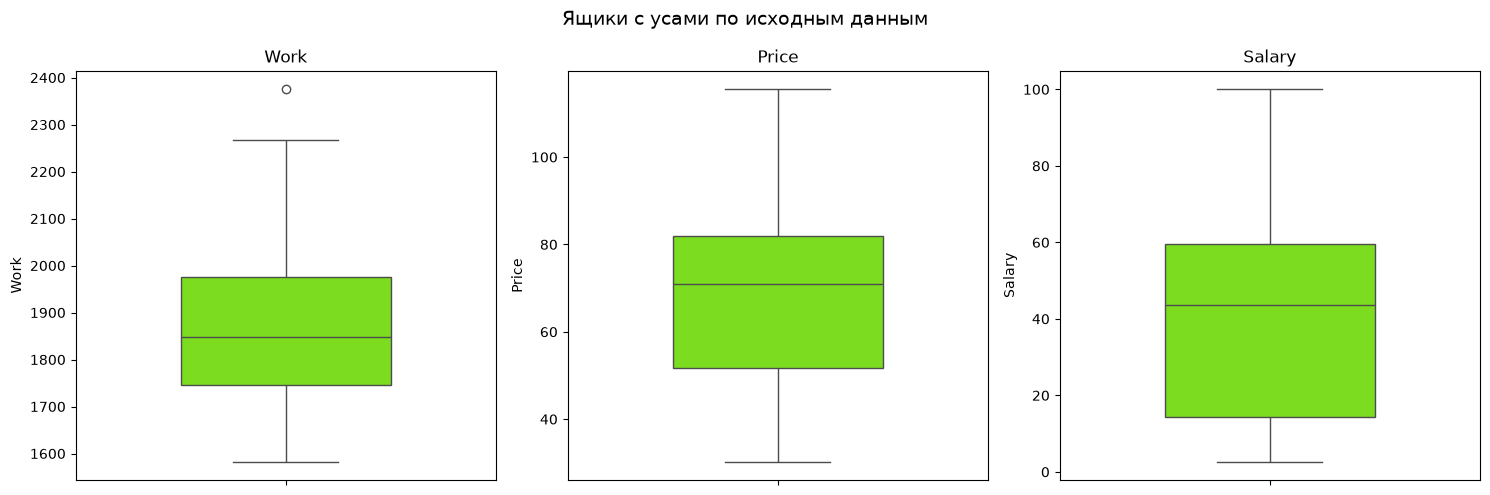

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
features = ["Work", "Price", "Salary"]
for ax, f in zip(axes, features):
    sns.boxplot(y=X_raw[f], ax=ax, color="lawngreen", width=0.5)
    ax.set_title(f)

fig.suptitle("Ящики с усами по исходным данным", fontsize=14)
plt.tight_layout()
plt.show()

In [9]:
df_raw.loc[X_raw["Work"].idxmax()]

City      Hong_Kong
Work           2375
Price          63.8
Salary         27.8
Name: 15, dtype: object

Единственный выброс — **Гонконг** по числу рабочих часов (2375 в год). Остальные значения в порядке

### Корреляции

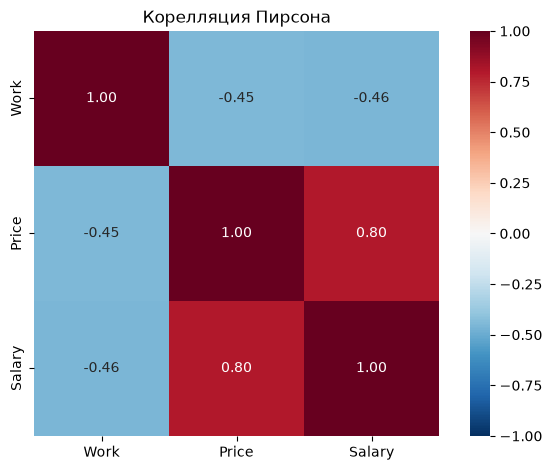

In [10]:
sns.heatmap(X_raw.corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True)
plt.title("Корелляция Пирсона")
plt.tight_layout()
plt.show()

**Наблюдения:**
- Цены и зарплаты сильно связаны: r = 0,80. Где высокие цены, там больше платят.
- Рабочие часы связаны с ними обратно (r = −0,45): где платят меньше, там работают больше по часам.

## Стандартизация

Шкалы признаков сильно различаются. Переводим каждый признак в z-оценки

In [24]:
scaler = StandardScaler()
X = scaler.fit_transform(X_raw)
X_scaled = pd.DataFrame(X, columns=["Work", "Price", "Salary"])
X_scaled.head()

,Work,Price,Salary
0,-0.962166,-0.212712,0.386095
1,-0.509827,-0.770489,-0.373488
2,1.577891,-1.522069,-1.145323
3,0.997969,-1.881316,-1.398517
4,-0.996961,0.174896,0.447351


In [13]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

## 3. Выбор числа кластеров

Перебираем `k` от 2 до 8 и смотрим две величины:
- **Inertia** — сумма квадратов расстояний от точек до центров их кластеров. Она всегда уменьшается с ростом `k`,
  поэтому ищем «локоть» — место, после которого уменьшение замедляется.
- **Коэффициент силуэта** — от −1 до 1, показывает, насколько точка ближе к своему кластеру, чем к соседнему

,inertia,silhouette,размеры кластеров
k,,,
2,61.12,0.470,"[21, 25]"
3,47.36,0.388,"[11, 25, 10]"
4,35.59,0.340,"[17, 10, 8, 11]"
5,27.92,0.369,"[8, 6, 14, 12, 6]"
6,23.21,0.373,"[5, 14, 7, 6, 8, 6]"
7,18.92,0.368,"[6, 5, 5, 8, 7, 12, 3]"
8,15.75,0.406,"[14, 8, 7, 2, 4, 1, 4, 6]"


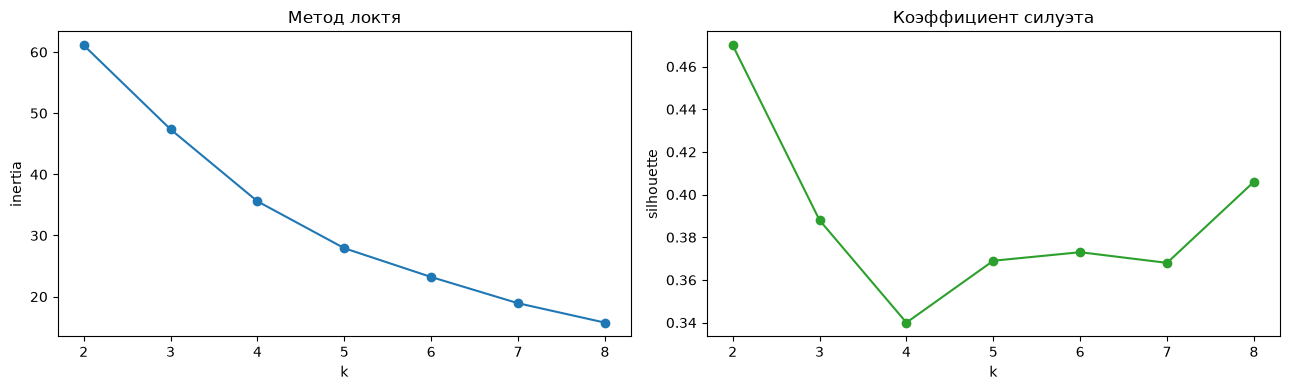

In [15]:
rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    rows.append({"k": k,
                 "inertia": round(km.inertia_, 2),
                 "silhouette": round(silhouette_score(X_scaled, km.labels_), 3),
                 "размеры кластеров": np.bincount(km.labels_)})
scores = pd.DataFrame(rows).set_index("k")
display(scores)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(scores.index, scores["inertia"], "o-")
axes[0].set_title("Метод локтя"); axes[0].set_xlabel("k"); axes[0].set_ylabel("inertia")
axes[1].plot(scores.index, scores["silhouette"], "o-", color="tab:green")
axes[1].set_title("Коэффициент силуэта"); axes[1].set_xlabel("k"); axes[1].set_ylabel("silhouette")
plt.tight_layout(); plt.show()

**Вывод**: Четкого локтя нет, лучшие метрики при k = 2, но данное деление будет "богатые-бедные", а при k = 8 уже есть кластер из 1 элемента. Выберем k = 3, как основное деление

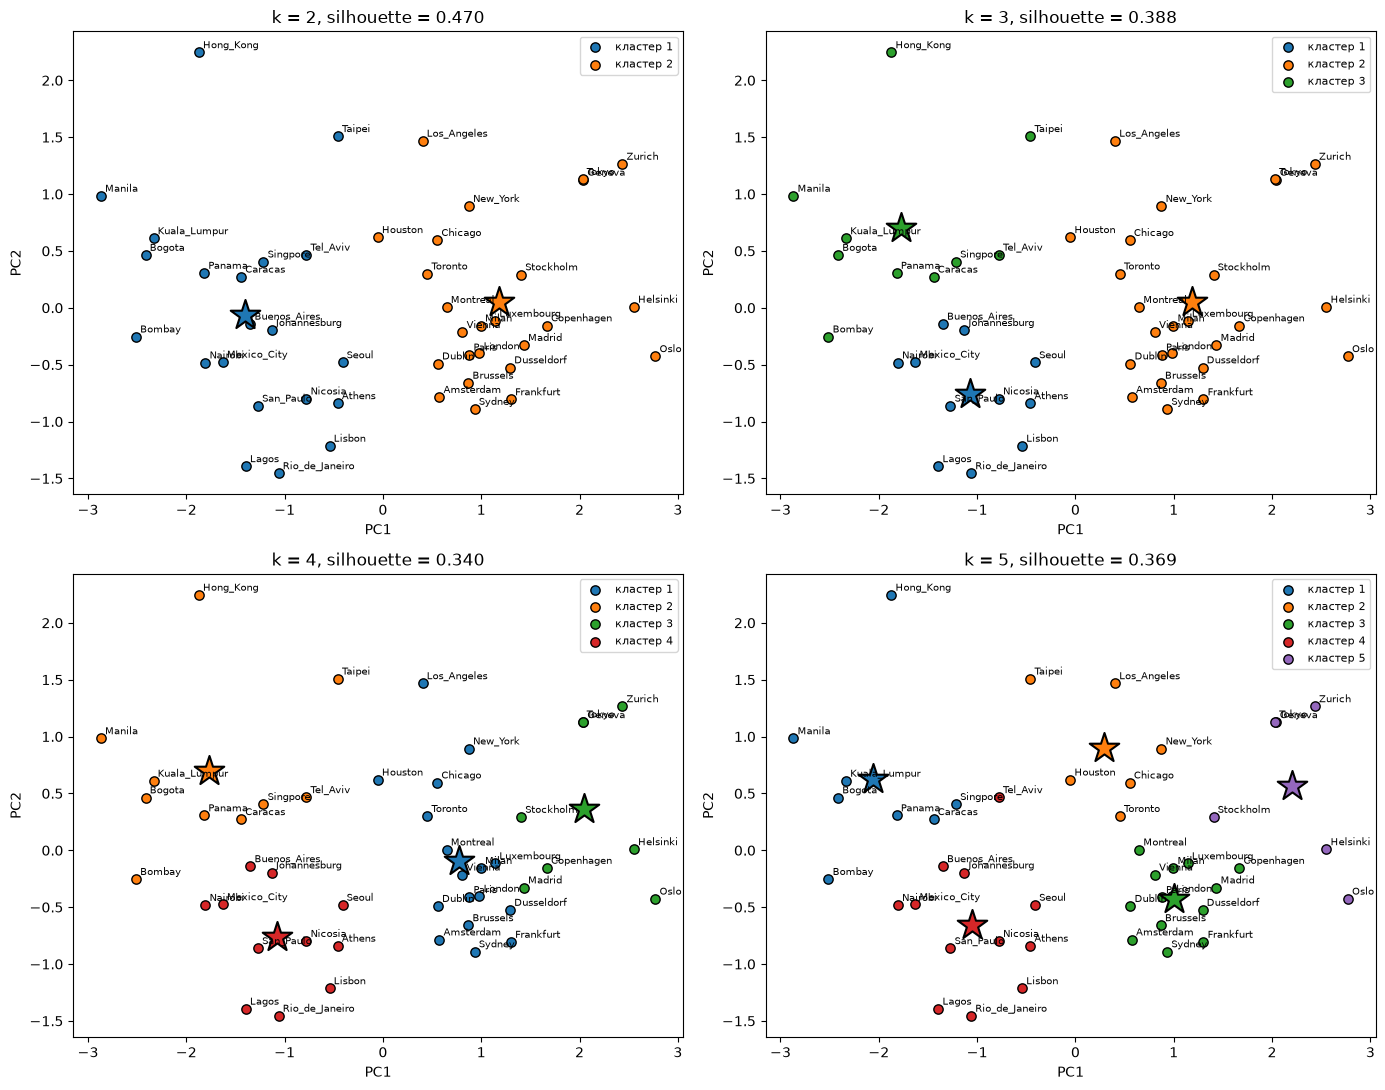

In [17]:
COLORS = plt.get_cmap("tab10")
def draw_clusters(ax, points, labels, centers, title, names=None):
    for c in range(len(centers)):
        m = labels == c
        ax.scatter(points[m, 0], points[m, 1], color=COLORS(c), s=45, edgecolor="k", label=f"кластер {c + 1}")
        ax.scatter(centers[c, 0], centers[c, 1], marker="*", s=500, color=COLORS(c), edgecolor="k", linewidth=1.5)
    if names is not None:
        for (x, y), name in zip(points, names):
            ax.annotate(name, (x, y), fontsize=7, xytext=(3, 3), textcoords="offset points")
    ax.set_title(title)


fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for ax, k in zip(axes.ravel(), [2, 3, 4, 5]):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    draw_clusters(ax, X_pca, km.labels_, pca.transform(km.cluster_centers_),
                  f"k = {k}, silhouette = {silhouette_score(X_scaled, km.labels_):.3f}", df["City"])
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

На графиках видно, что происходит дробление кластера с увеличение k на два поменьше или "перекрестное" деление у приграничных городов, как при переходе от k = 4 до k = 5

У KMeans есть один параметр, который можно настроить. Инициализацию кластеров в kmeans++ или random. Хочется замерить, влияет ли выбор на метрики

inertia_средняя        inertia_худшая       
init       k-means++ random      k-means++ random
k                                                
2              61.12  61.12          61.12  61.12
3              48.56  48.20          50.65  51.46
4              39.22  40.07          42.64  46.67
5              31.43  32.21          36.64  42.97
6              25.07  26.55          30.11  29.95
7              21.38  23.51          23.82  27.97
8              17.26  21.60          21.34  24.20

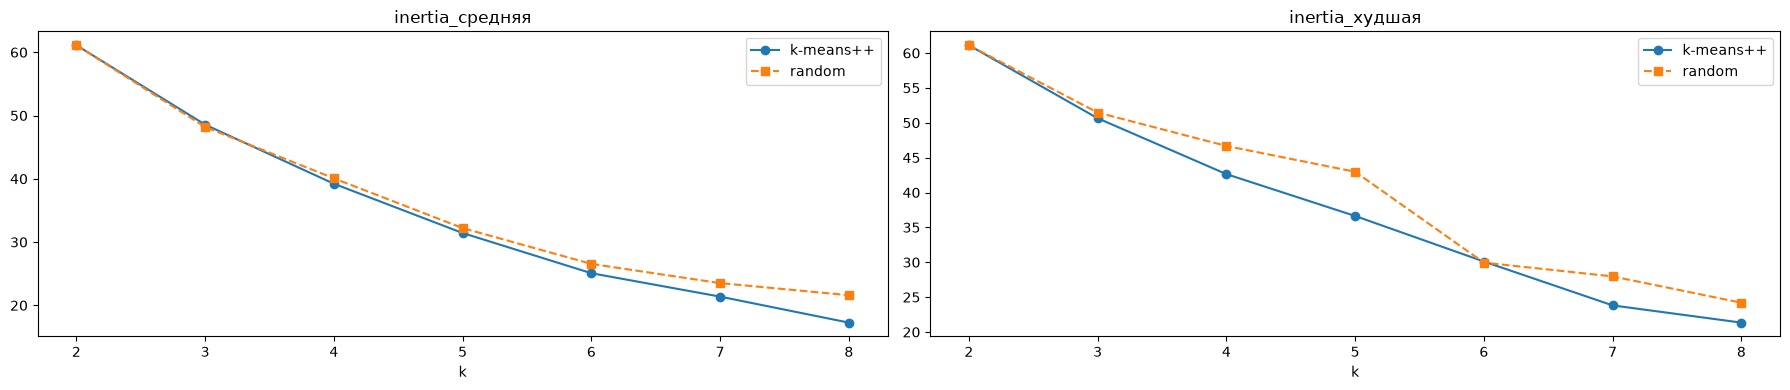

In [18]:
rows = []
for k in range(2, 9):
    for init in ["k-means++", "random"]:
        res = [KMeans(n_clusters=k, init=init, n_init=1, random_state=run).fit(X_scaled) for run in range(10)]
        rows.append({"k": k, "init": init,
                     "inertia_средняя": np.mean([m.inertia_ for m in res]),
                     "inertia_худшая": np.max([m.inertia_ for m in res]),
                     })
by_k = pd.DataFrame(rows)
display(by_k.pivot(index="k", columns="init").round(2))

fig, axes = plt.subplots(1, 2, figsize=(18, 4))
for ax, col in zip(axes, ["inertia_средняя", "inertia_худшая"]):
    for init, style in [("k-means++", "o-"), ("random", "s--")]:
        part = by_k[by_k["init"] == init]
        ax.plot(part["k"], part[col], style, label=init)
    ax.set_title(col); ax.set_xlabel("k"); ax.legend()
plt.tight_layout(); plt.show()

**Вывод**: особой разницы нет,  можно принебречь в данной задаче выбором инициализации, оставив kmeans++, который по умолчанию в библиотеке

**Итоговая модель**

Берём **`k = 3`**: силуэт 0.39, все кластеры достаточно
крупные (10–25 городов), и, как видно ниже, третий кластер даёт содержательное различие —
он отделяет города с очень длинным рабочим годом.

k = 3, silhouette = 0.388
Размеры кластеров: [11 25 10]


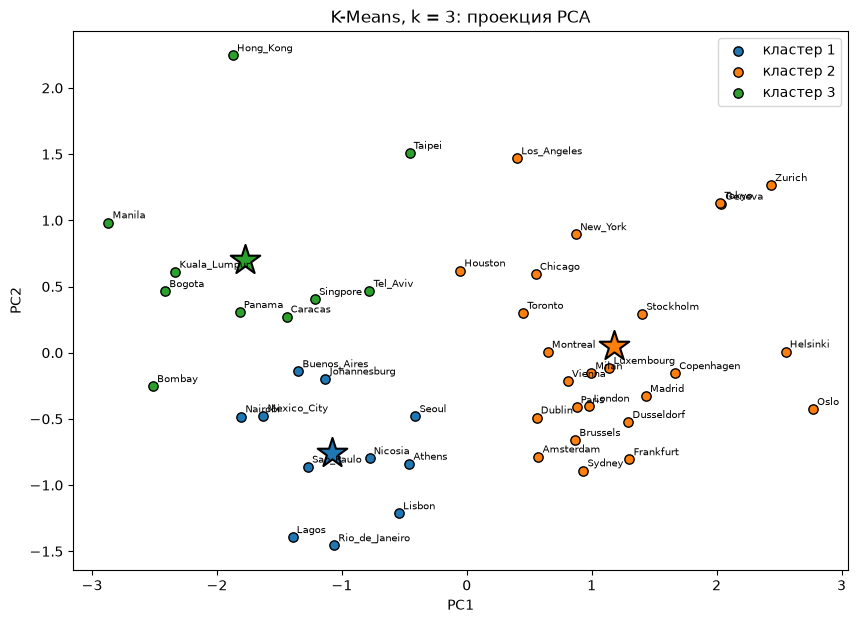

In [26]:
K = 3
kmeans = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X_scaled)
df["cluster"] = kmeans.labels_
centers =  scaler.inverse_transform(kmeans.cluster_centers_)  # центроиды в исходных единицах

print(f"k = {K}, silhouette = {silhouette_score(X_scaled, df['cluster']):.3f}")
print("Размеры кластеров:", np.bincount(df["cluster"]))

fig, ax = plt.subplots(figsize=(10, 7))
draw_clusters(ax, X_pca, df["cluster"].values, pca.transform(kmeans.cluster_centers_),
              f"K-Means, k = {K}: проекция PCA", df["City"])
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend(); plt.show()

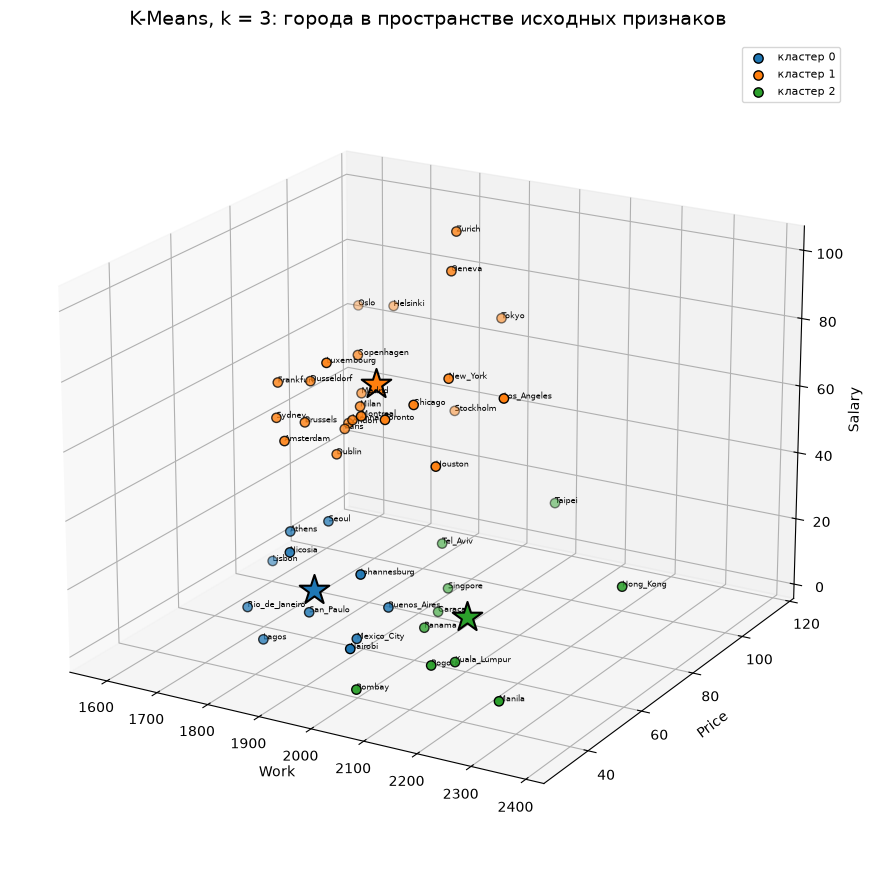

In [28]:
fig = plt.figure(figsize=(16, 9))
elev, azim = (20, -60)
ax = fig.add_subplot(1, 1, 1, projection="3d")

for c in range(K):
    m = df["cluster"] == c
    ax.scatter(df.loc[m, "Work"], df.loc[m, "Price"], df.loc[m, "Salary"],
               color=COLORS(c), s=45, edgecolor="k", label=f"кластер {c}")
    ax.scatter(*centers[c], marker="*", s=500, color=COLORS(c),
               edgecolor="k", linewidth=1.5)

for _, r in df.iterrows():
    ax.text(r["Work"], r["Price"], r["Salary"], r["City"], fontsize=6)

ax.set_xlabel("Work")
ax.set_ylabel("Price")
ax.set_zlabel("Salary")
ax.view_init(elev=elev, azim=azim)

fig.axes[0].legend(fontsize=8)
plt.suptitle(f"K-Means, k = {K}: города в пространстве исходных признаков", fontsize=14)
plt.tight_layout()
plt.show()


In [34]:
profile = pd.DataFrame(centers, columns=["Work", "Price", "Salary"]).round(1)
profile["число городов"] = np.bincount(df["cluster"])
profile["города"] = [", ".join(df.loc[df["cluster"] == c, "City"]) for c in range(K)]
pd.set_option("display.max_colwidth", None)
profile

,Work,Price,Salary,число городов,города
0,1855.5,50.8,16.6,11,"Athens, Buenos_Aires, Johannesburg, Lagos, Lisbon, Mexico_City, Nairobi, Nicosia, Rio_de_Janeiro, San_Paulo, Seoul"
1,1789.2,85.0,59.0,25,"Amsterdam, Brussels, Chicago, Copenhagen, Dublin, Dusseldorf, Frankfurt, Geneva, Helsinki, Houston, London, Los_Angeles, Luxembourg, Madrid, Milan, Montreal, New_York, Oslo, Paris, Stockholm, Sydney, Tokyo, Toronto, Vienna, Zurich"
2,2133.5,54.2,16.1,10,"Bogota, Bombay, Caracas, Hong_Kong, Kuala_Lumpur, Manila, Panama, Singpore, Taipei, Tel_Aviv"


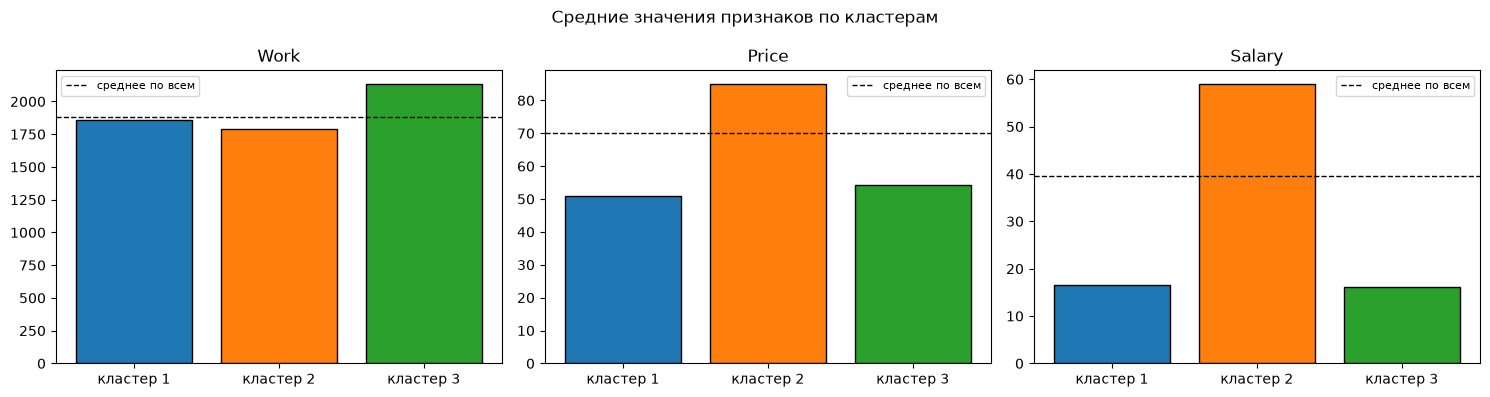

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, f in zip(axes, ["Work", "Price", "Salary"]):
    ax.bar([f"кластер {c + 1}" for c in range(K)], profile[f], color=[COLORS(c) for c in range(K)], edgecolor="k")
    ax.axhline(df[f].mean(), color="k", ls="--", lw=1, label="среднее по всем")
    ax.set_title(f); ax.legend(fontsize=8)
plt.suptitle("Средние значения признаков по кластерам")
plt.tight_layout(); plt.show()

## Выводы


- **Кластер 1 — города развивающихся стран и юга Европы** (Афины, Лиссабон, Никосия, Сеул,
  Мексика, Аргентина, Бразилия, Йоханнесбург, Найроби, Лагос).
  Цены и зарплаты заметно ниже среднего, но лучше третьего кластера, а количество рабочих часов близко к среднему.

- **Кластер 2 — крупные и богатые города** (Западная Европа, Северная Америка, Австралия, Токио).
  Самые высокие цены и зарплаты и при этом самый  меньше всех рабочих часов. Зарплаты здесь
 сильно выше, чем в двух других кластерах, а цены — только в 1,5 раза.

- **Кластер 2 — города Азии и Латинской Америки с длинным рабочим годом** (Китай, 
  Сингапур, Манила, Куала-Лумпур, Бомбей, Богота, Каракас, Панама, Тель-Авив). По ценам и зарплатам
  они почти такие же, как кластер 1, но работают сильно больше.

**Дополнительный эксперимент**
Мы выбрали k = 3, что делит довольно крупно кластеры, может стоило выбрать k побольше?
Выберем k = 5

k = 5, silhouette = 0.369
Размеры кластеров: [ 8  6 14 12  6]


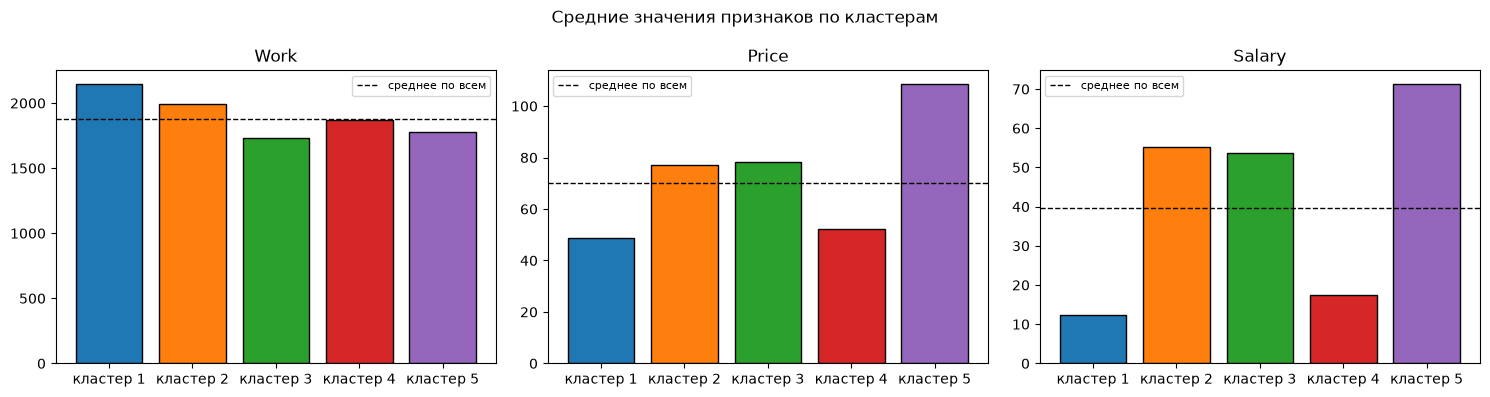

In [40]:
K = 5
kmeans = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X_scaled)
df["cluster"] = kmeans.labels_
centers =  scaler.inverse_transform(kmeans.cluster_centers_)

print(f"k = {K}, silhouette = {silhouette_score(X_scaled, df['cluster']):.3f}")
print("Размеры кластеров:", np.bincount(df["cluster"]))


profile = pd.DataFrame(centers, columns=["Work", "Price", "Salary"]).round(1)


fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, f in zip(axes, ["Work", "Price", "Salary"]):
    ax.bar([f"кластер {c + 1}" for c in range(K)], profile[f], color=[COLORS(c) for c in range(K)], edgecolor="k")
    ax.axhline(df[f].mean(), color="k", ls="--", lw=1, label="среднее по всем")
    ax.set_title(f); ax.legend(fontsize=8)
plt.suptitle("Средние значения признаков по кластерам")
plt.tight_layout(); plt.show()

В первом случае, когда k = 3, то четко выделить кластеры было легко, а на данной картинке, отличия видны, но интерпретировать сложнее, поэтому конечным будет k = 3.